In [1]:
# Ejemplo de regresión lineal simple en Python
import warnings
warnings.filterwarnings("ignore")  # Suprimir warnings

import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
from scipy.stats import t
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import OLSInfluence

In [ ]:
# Cargar el dataset 'trees' equivalente
#from pydataset import data
#trees = data('trees')
#print(trees.head())

# Cargar el dataset 'trees' equivalente
trees = pd.read_csv('trees.csv')
trees.head()



,Unnamed: 0,Girth,Height,Volume
0,1,8.3,70,10.3
1,2,8.6,65,10.3
2,3,8.8,63,10.2
3,4,10.5,72,16.4
4,5,10.7,81,18.8


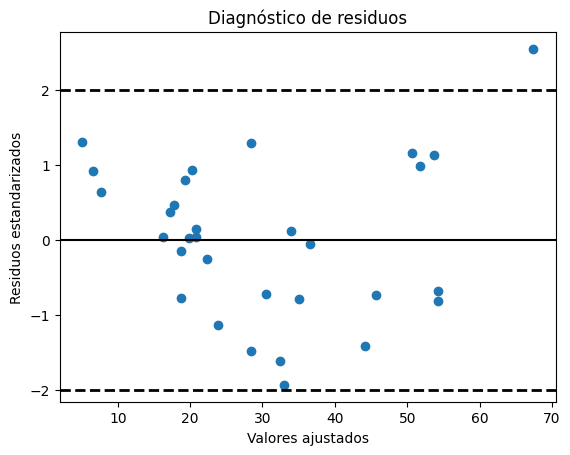

In [ ]:
# Estimar el modelo lineal: Volume ~ Girth
X = sm.add_constant(trees['Girth'])  # Agregar intercepto
y = trees['Volume']
modelo = sm.OLS(y, X).fit()

# Obtener residuos y residuos estandarizados
influence = OLSInfluence(modelo)
residuos_estandarizados = influence.resid_studentized_internal
valores_ajustados = modelo.fittedvalues

# Graficar residuos estandarizados vs valores ajustados
plt.scatter(valores_ajustados, residuos_estandarizados)
plt.axhline(y=2, linestyle='dashed', linewidth=2, color='black')
plt.axhline(y=-2, linestyle='dashed', linewidth=2, color='black')
plt.axhline(y=0, color='black')
plt.xlabel('Valores ajustados')
plt.ylabel('Residuos estandarizados')
plt.title('Diagnóstico de residuos')
plt.show()

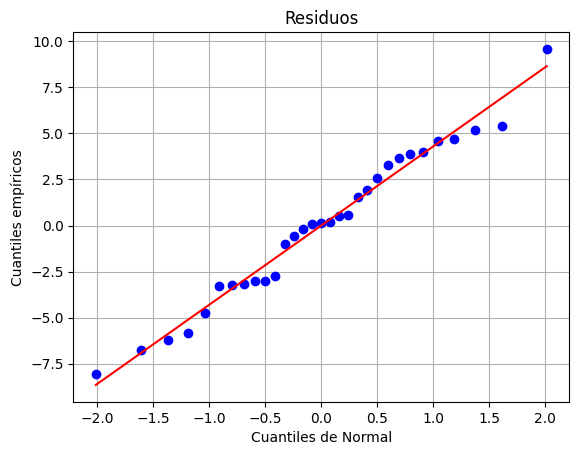

In [ ]:
# Obtener los residuos del modelo
residuo = modelo.resid

# Gráfico QQ
stats.probplot(residuo, dist="norm", plot=plt)
plt.xlabel("Cuantiles de Normal")
plt.ylabel("Cuantiles empíricos")
plt.title("Residuos")
plt.grid(True)
plt.show()

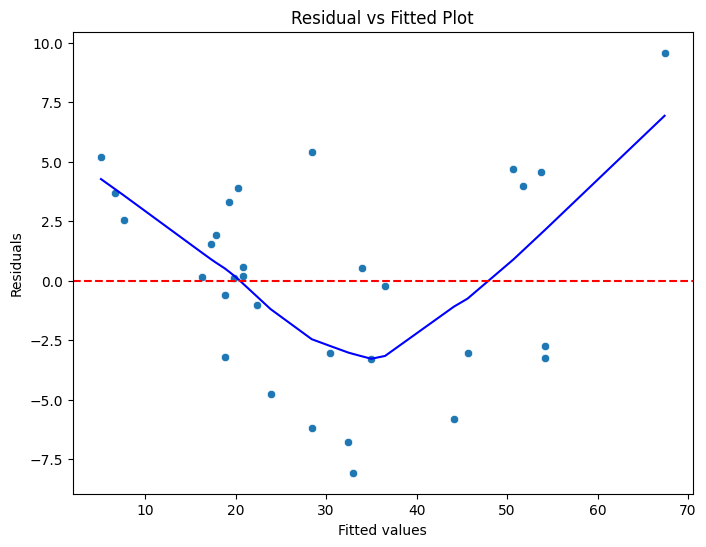

In [ ]:
# Valores ajustados y residuos
fitted = modelo.fittedvalues
residuo = modelo.resid

# Crear el gráfico
plt.figure(figsize=(8, 6))
sns.scatterplot(x=fitted, y=residuo)

# Suavizado LOESS
lowess = sm.nonparametric.lowess
suavizado = lowess(residuo, fitted)
plt.plot(suavizado[:, 0], suavizado[:, 1], color='blue')

# Línea horizontal en y = 0
plt.axhline(y=0, color='red', linestyle='dashed')

# Etiquetas y estilo
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residual vs Fitted Plot")
sns.set_theme(style="whitegrid")
plt.show()

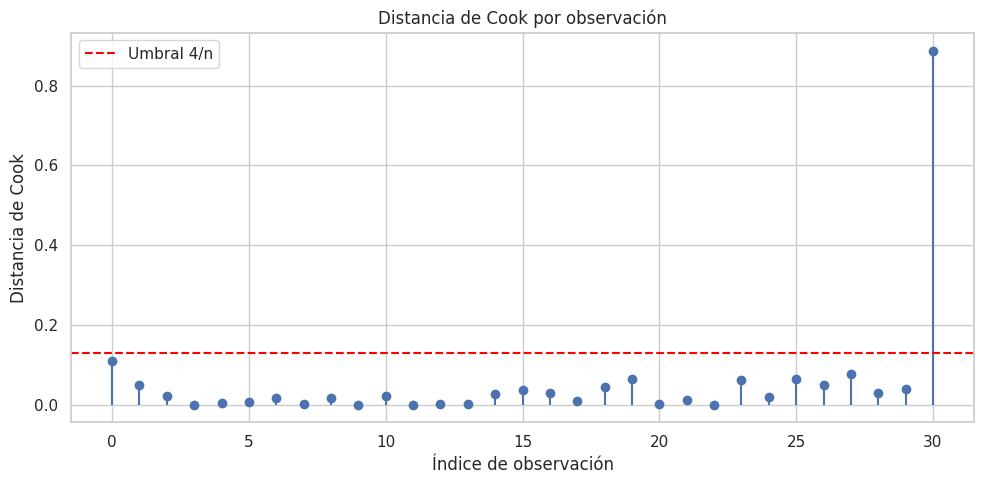

In [ ]:
# Suponiendo que ya ajustaste el modelo
X = sm.add_constant(trees["Girth"])
y = trees["Volume"]
modelo = sm.OLS(y, X).fit()

# Obtener distancia de Cook
influence = modelo.get_influence()
cooks_d = influence.cooks_distance[0]

# Graficar sin el parámetro conflictivo
plt.figure(figsize=(10, 5))
plt.stem(range(len(cooks_d)), cooks_d, markerfmt="o", basefmt=" ")
plt.axhline(4 / len(trees), color='red', linestyle='--', label='Umbral 4/n')
plt.title("Distancia de Cook por observación")
plt.xlabel("Índice de observación")
plt.ylabel("Distancia de Cook")
plt.legend()
plt.tight_layout()

In [ ]:
fig.savefig("figura5.pdf")

In [ ]:
# Resumen del modelo
resultados = modelo.summary()
print(resultados)

# Coeficiente de determinación (R²)
R2 = modelo.rsquared
print(f"Coeficiente de determinación: {R2:.4f}")


                            OLS Regression Results                            
Dep. Variable:                 Volume   R-squared:                       0.935
Model:                            OLS   Adj. R-squared:                  0.933
Method:                 Least Squares   F-statistic:                     419.4
Date:                Fri, 29 Aug 2025   Prob (F-statistic):           8.64e-19
Time:                        14:04:05   Log-Likelihood:                -87.822
No. Observations:                  31   AIC:                             179.6
Df Residuals:                      29   BIC:                             182.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -36.9435      3.365    -10.978      0.0

In [ ]:
print(f"R² ajustado: {modelo.rsquared_adj:.4f}")

R² ajustado: 0.9331


In [ ]:
xi = trees["Girth"].values
yi = trees["Volume"].values
n = len(xi)

# Cálculos manuales
Sxx = np.sum(xi**2) - (np.sum(xi)**2) / n
Sxy = np.sum(xi * yi) - (np.sum(xi) * np.sum(yi)) / n
SST = np.sum(yi**2) - n * (np.mean(yi)**2)

# Coeficiente de correlación muestral
r = Sxy / np.sqrt(Sxx * SST)
print(f"Salida coeficiente de correlación muestral: {r:.8f}")

# También conocido como coeficiente de correlación de Pearson
pearson_r, p_value = stats.pearsonr(xi, yi)
print(f"Pearson r: {pearson_r:.8f}, p-valor: {p_value:.4e}")

Salida coeficiente de correlación muestral: 0.96711937
Pearson r: 0.96711937, p-valor: 8.6443e-19


In [ ]:
# Ajustar el modelo lineal simple
X = sm.add_constant(trees["Girth"])  # Variable independiente
y = trees["Volume"]                  # Variable dependiente
modelo = sm.OLS(y, X).fit()
# Mostrar resumen del modelo
print(modelo.summary())
# Extraer R²
R2 = modelo.rsquared
print(f"Coeficiente de determinación: {R2:.7f}")

                            OLS Regression Results                            
Dep. Variable:                 Volume   R-squared:                       0.935
Model:                            OLS   Adj. R-squared:                  0.933
Method:                 Least Squares   F-statistic:                     419.4
Date:                Fri, 29 Aug 2025   Prob (F-statistic):           8.64e-19
Time:                        14:08:50   Log-Likelihood:                -87.822
No. Observations:                  31   AIC:                             179.6
Df Residuals:                      29   BIC:                             182.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -36.9435      3.365    -10.978      0.0

In [ ]:
# Cálculos previos (ya definidos antes)
Sxx = np.sum(xi**2) - (np.sum(xi)**2) / n
Sxy = np.sum(xi * yi) - (np.sum(xi) * np.sum(yi)) / n
SST = np.sum(yi**2) - n * (np.mean(yi)**2)

# Estimación de beta1
beta1_est = Sxy / Sxx

# Error cuadrático residual
SSE = SST - beta1_est * Sxy
varSigma_est = SSE / (n - 2)

# Estadístico t para beta1
T0 = beta1_est / np.sqrt(varSigma_est / Sxx)
p_valor = 2 * (1 - t.cdf(np.abs(T0), df=n - 2))
print(f"p-valor de beta1: {p_valor:.4e}")

p-valor de beta1: 0.0000e+00


In [ ]:
# Estadístico t para r
T0r = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
p_valorR = 2 * (1 - t.cdf(np.abs(T0r), df=n - 2))
print(f"p-valor de R: {p_valorR:.4e}")

p-valor de R: 0.0000e+00


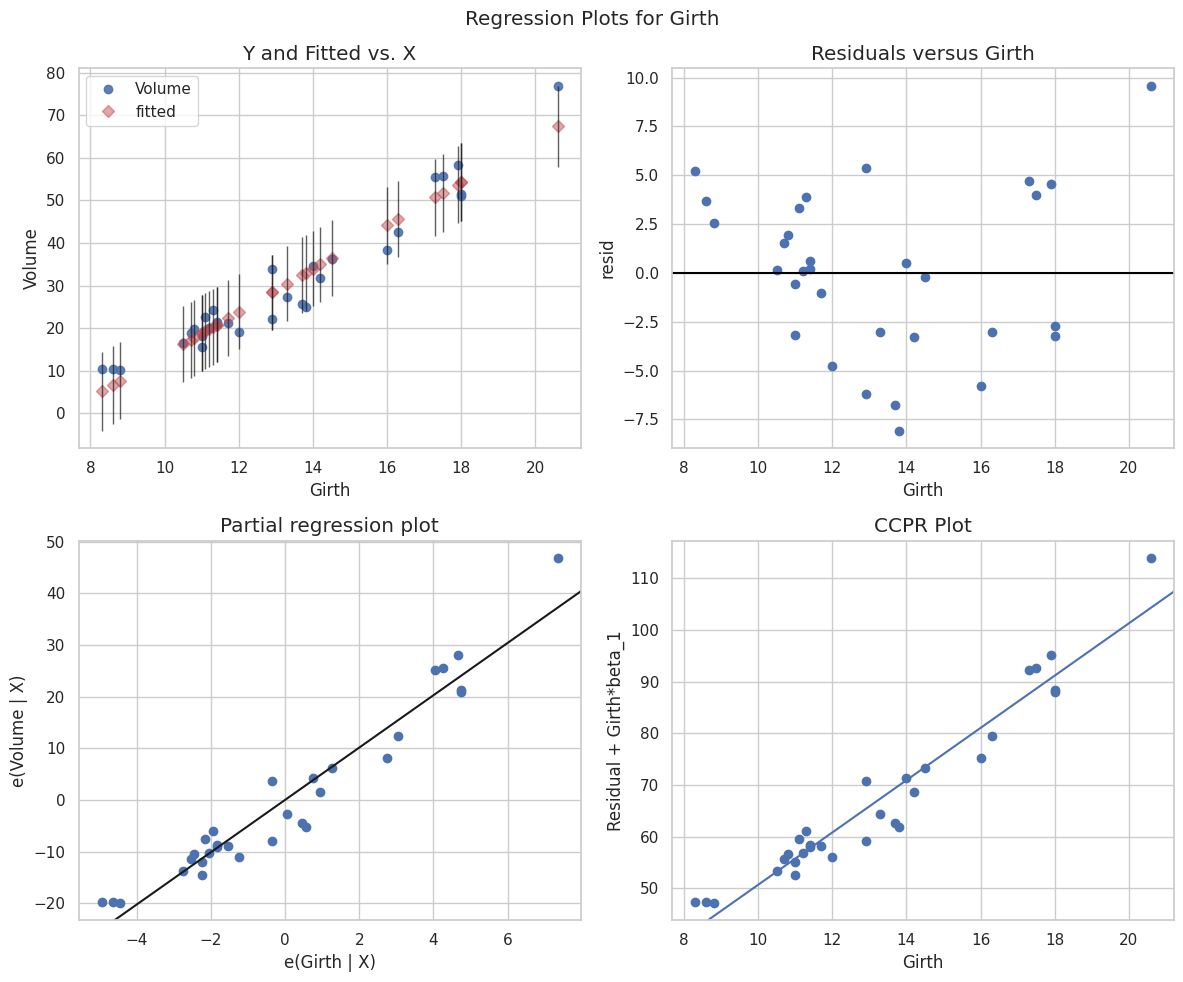

In [ ]:
fig = plt.figure(figsize=(12, 10))
sm.graphics.plot_regress_exog(modelo, "Girth", fig=fig)
plt.tight_layout()
plt.show()